<a href="https://colab.research.google.com/github/RFUNN/-/blob/main/Polynomial_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Salary Prediction comparing Polynomial Regression and Simple Linear Regression**
---
<p align="justify">
 A specific company has an internal salary policy according to the position and hierarchy of each employee. For example, when an employee enters the company, he will first enter the level of business analyst, then he will become a junior consultant, senior consultant, etc. Level 10 is the highest in the hierarchy and represents the position of CEO of the company with the highest salary respectively. For each level the company pays a respective salary predetermined in the company's policies.


<p align=center>
<img src="https://drive.google.com/uc?id=1Jwgg_JaLlD5gkBixAwtO--sG9z3aRScQ" width="50%"></p>

<p align="justify">
The company contacted a candidate for a new job due to its excellent work experience and curriculum. Through interviews with the HR department, this candidate said that he had been working for 2 years in the position of Regent Manager in his previous job and his salary expectation for the new job would be at least equal to his previous job, something equivalent to $160k a year.

<p align="justify">
First the company wants to know if the position that he worked in his previous job really corresponds to a salary of $160k or if the candidate was bluffing to get a higher salary.

<p align="justify">
Through internet research on sites such as Glassdoor and Lovemondays, the HR department found out how much the candidate's previous company paid for different positions annually and according to this history the company wants to know if Regent Manager's position really would correspond to $160k a year.

<p align="justify">
According to the record, the position of Regent Manager corresponds to level 6, however, as the candidate said he had been working for 2 years in this position, the HR department decided to do the calculations and projections considering level 6.5 instead of 6.

<p align="justify">
The historical data that is important for the HR department are:

<p align="justify">
-The level in the hierarchy ranging from 1 to 10.
<p align="justify">
-The salary corresponding to each level.

<p align=center>
<img src="https://drive.google.com/uc?id=13Keg3YTXxgQ76vcM6L9ufXyqfTtN9Vqz" width="60%"></p>


<p align=center>
<img src="https://drive.google.com/uc?id=1XPTuOjwjgrVi0UNxSoBXqA_z9nPag1K1" width="60%"></p>


Then the HR department of the company decided to make a regression with the numbers got in the internet research. They decided to make a **simple linear regression** first and then a **polynomial regression**, to conclude in the end which is the best method to be applied in this case.



As the company database is small and has only 10 levels, all data were considered as a Training set, not considering any data for the Test set and already applying the projection to level 6.5 directly. Then it is possible to verify the salary projections using **linear regression** and **polynomial regression** respectively.

**Code description is explained below:**

## **Importing the libraries**


The 3 libraries needed for the project are imported.
- Pandas for data manipulation and analysis
- Numpy for mathematical operations
- Matplotlib for graphical visualizations

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## **Importing the data set**


The .csv file containing his previous company's database is imported.

Separating **Level** as the corresponding X-axis values and the **Salary** as Y-axis values, it was obtained final data set..

The values of the database header and how they are distributed can be viewed in the image below:

In [2]:
import numpy as np
import pandas as pd

dataset= pd.read_csv('https://raw.githubusercontent.com/RFUNN/Lab/refs/heads/main/Position_Salaries.csv')
X= dataset.iloc[:,1:2].values
Y= dataset.iloc[:,2].values
dataset.head()

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


## **Fitting Simple Linear Regression to the Dataset**

The **sklearn.linear_model** library was used to apply the **Simple Linear Regression** method.

Using the **Training set** of X and Y values, a prediction curve is created.

In [3]:
from sklearn.linear_model import LinearRegression
lin_reg= LinearRegression()
lin_reg.fit(X,Y)

LinearRegression()

## **Visualising the Linear Regression Results**

A graph was plotted with the real values of **X-axis values VERSUS Y-axis values** (red dots), present in the **Training set**. From these previously mentioned values, the model generated a prediction curve (blue line).

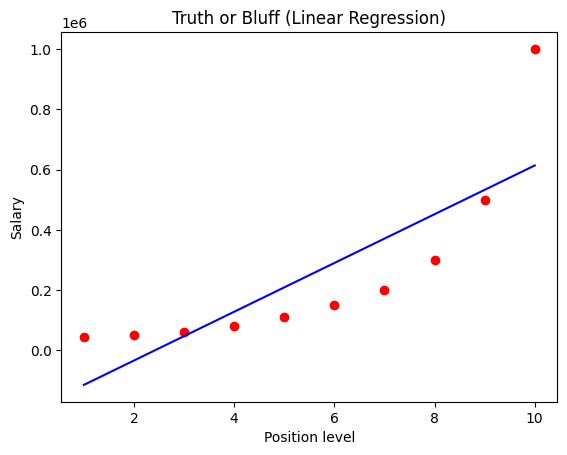

In [5]:
import matplotlib.pyplot as plt

plt.scatter(X,Y,color='red')
plt.plot(X,lin_reg.predict(X),color='blue')
plt.title('Truth or Bluff (Linear Regression)')
plt.xlabel('Position level')
plt.ylabel('Salary')
plt.show()

## **Predicting a new result with Linear Regression**


The requested value **Level=6.5** is projected using the Linear Regression, giving an output as salary.

In [6]:
lin_reg.predict([[6.5]])

array([330378.78787879])

## **Fitting Polynomial Regression to the dataset**

The **sklearn.preprocessing** library was used to apply the **Polynomial Regression** method.

Using the **Training set** of X and Y values, a prediction curve is created.

In [7]:
from sklearn.preprocessing import PolynomialFeatures
poly_reg= PolynomialFeatures(degree=4)
X_poly= poly_reg.fit_transform(X)

poly_reg.fit(X_poly,Y)
lin_reg_2= LinearRegression()
lin_reg_2.fit(X_poly,Y)


LinearRegression()

## **Evaluating the Model Performance**

obs:This model has only one single sample as test=$160k, because of that the R-squared method for accuracy is not applicable in this method. It requires at least 2 samples.

The **sklearn.metrics** library was used to apply the **R square** method and verify the accuracy of this model.

In [8]:
from sklearn.metrics import r2_score
r2_score(Y_test,Y_pred)

NameError: name 'Y_test' is not defined

## **Visualising the Polynomial Regression Results**

A graph was plotted with the real values of **X-axis values VERSUS Y-axis values** (red dots), present in the **Training set**. From these previously mentioned values, the model generated a prediction curve (blue line).

In [9]:
X_grid = np.arange(min(X), max(X), 0.1)
X_grid = X_grid.reshape((len(X_grid), 1))
plt.scatter(X,Y,color='red')
plt.plot(X_grid, lin_reg_2.predict(poly_reg.fit_transform(X_grid)), color = 'blue')
plt.title('Truth or Bluff (Polynomial Regression)')
plt.xlabel('Position level')
plt.ylabel('Salary')
plt.show()

TypeError: only 0-dimensional arrays can be converted to Python scalars

## **Predicting a new result with Polynomial Regression**

The requested value **Level=6.5** is projected using the Polynomial Regression, giving an output as salary.

In [ ]:
lin_reg_2.predict(poly_reg.fit_transform([[6.5]]))

array([158862.45265155])

## **Evaluating the Model Performance**

obs:This model has only one single sample as test=$160k, because of that the R-squared method for accuracy is not applicable in this method. It requires at least 2 samples.

The **sklearn.metrics** library was used to apply the **R square** method and verify the accuracy of this model.

In [ ]:
from sklearn.metrics import r2_score
r2_score(Y_test,Y_pred)

NameError: ignored

## **Conclusion**

<p align="justify">
It was evident from the graphs that the most accurate value to be considered will be the salary projection using the polynomial regression, in this case is possible to realize that the candidate was not bluffing, getting a result around $160k as said by the candidate.
<p align="justify">
The projected salary value is also lower than the value found for the linear regression, benefiting the company's costs and consequently increasing its  profit.